### Загрузка данных и их объединение в общий датасет

In [9]:
import pandas as pd


train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')


train_len = len(train)

print(f"Train size: {train_len}, Test size: {len(test)}")


# Конкатенация (игнорируем исходные индексы)
df = pd.concat([train, test], ignore_index=True)
df

Train size: 1460, Test size: 1459


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500.0
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500.0
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500.0
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000.0
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2914,2915,160,RM,21.0,1936,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2006,WD,Normal,NaN
2915,2916,160,RM,21.0,1894,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2006,WD,Abnorml,NaN
2916,2917,20,RL,160.0,20000,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2006,WD,Abnorml,NaN
2917,2918,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,NaN


### Приведение к общему стилю строк (названия столбцов)

In [10]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.head(10)

,id,mssubclass,mszoning,lotfrontage,lotarea,street,alley,lotshape,landcontour,utilities,...,poolarea,poolqc,fence,miscfeature,miscval,mosold,yrsold,saletype,salecondition,saleprice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500.0
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500.0
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500.0
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000.0
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000.0
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000.0
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000.0
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000.0
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900.0
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000.0


In [11]:
priznaki = len(df.columns)
print(f"Кол-во признаков: {priznaki}")

Кол-во признаков: 81


### Приведение к общему виду строк (значений столбцов с типом "str")

In [12]:
strings = list(df.dtypes[df.dtypes == 'str'].index)
print(strings)
print(len(strings))
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')
    
df.head(10)

['mszoning', 'street', 'alley', 'lotshape', 'landcontour', 'utilities', 'lotconfig', 'landslope', 'neighborhood', 'condition1', 'condition2', 'bldgtype', 'housestyle', 'roofstyle', 'roofmatl', 'exterior1st', 'exterior2nd', 'masvnrtype', 'exterqual', 'extercond', 'foundation', 'bsmtqual', 'bsmtcond', 'bsmtexposure', 'bsmtfintype1', 'bsmtfintype2', 'heating', 'heatingqc', 'centralair', 'electrical', 'kitchenqual', 'functional', 'fireplacequ', 'garagetype', 'garagefinish', 'garagequal', 'garagecond', 'paveddrive', 'poolqc', 'fence', 'miscfeature', 'saletype', 'salecondition']
43


,id,mssubclass,mszoning,lotfrontage,lotarea,street,alley,lotshape,landcontour,utilities,...,poolarea,poolqc,fence,miscfeature,miscval,mosold,yrsold,saletype,salecondition,saleprice
0,1,60,rl,65.0,8450,pave,NaN,reg,lvl,allpub,...,0,NaN,NaN,NaN,0,2,2008,wd,normal,208500.0
1,2,20,rl,80.0,9600,pave,NaN,reg,lvl,allpub,...,0,NaN,NaN,NaN,0,5,2007,wd,normal,181500.0
2,3,60,rl,68.0,11250,pave,NaN,ir1,lvl,allpub,...,0,NaN,NaN,NaN,0,9,2008,wd,normal,223500.0
3,4,70,rl,60.0,9550,pave,NaN,ir1,lvl,allpub,...,0,NaN,NaN,NaN,0,2,2006,wd,abnorml,140000.0
4,5,60,rl,84.0,14260,pave,NaN,ir1,lvl,allpub,...,0,NaN,NaN,NaN,0,12,2008,wd,normal,250000.0
5,6,50,rl,85.0,14115,pave,NaN,ir1,lvl,allpub,...,0,NaN,mnprv,shed,700,10,2009,wd,normal,143000.0
6,7,20,rl,75.0,10084,pave,NaN,reg,lvl,allpub,...,0,NaN,NaN,NaN,0,8,2007,wd,normal,307000.0
7,8,60,rl,NaN,10382,pave,NaN,ir1,lvl,allpub,...,0,NaN,NaN,shed,350,11,2009,wd,normal,200000.0
8,9,50,rm,51.0,6120,pave,NaN,reg,lvl,allpub,...,0,NaN,NaN,NaN,0,4,2008,wd,abnorml,129900.0
9,10,190,rl,50.0,7420,pave,NaN,reg,lvl,allpub,...,0,NaN,NaN,NaN,0,1,2008,wd,normal,118000.0


### Просмотр каждой колонки

In [13]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

id
[1 2 3 4 5]
2919

mssubclass
[ 60  20  70  50 190]
16

mszoning
<StringArray>
['rl', 'rm', 'c_(all)', 'fv', 'rh']
Length: 5, dtype: str
5

lotfrontage
[65. 80. 68. 60. 84.]
128

lotarea
[ 8450  9600 11250  9550 14260]
1951

street
<StringArray>
['pave', 'grvl']
Length: 2, dtype: str
2

alley
<StringArray>
[nan, 'grvl', 'pave']
Length: 3, dtype: str
2

lotshape
<StringArray>
['reg', 'ir1', 'ir2', 'ir3']
Length: 4, dtype: str
4

landcontour
<StringArray>
['lvl', 'bnk', 'low', 'hls']
Length: 4, dtype: str
4

utilities
<StringArray>
['allpub', 'nosewa', nan]
Length: 3, dtype: str
2

lotconfig
<StringArray>
['inside', 'fr2', 'corner', 'culdsac', 'fr3']
Length: 5, dtype: str
5

landslope
<StringArray>
['gtl', 'mod', 'sev']
Length: 3, dtype: str
3

neighborhood
<StringArray>
['collgcr', 'veenker', 'crawfor', 'noridge', 'mitchel']
Length: 5, dtype: str
25

condition1
<StringArray>
['norm', 'feedr', 'posn', 'artery', 'rrae']
Length: 5, dtype: str
9

condition2
<StringArray>
['norm', 'artery'

### Распределение цен на дом

<Axes: xlabel='saleprice', ylabel='Count'>

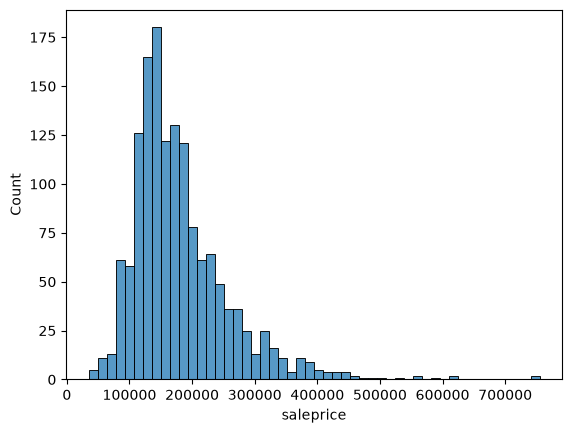

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.histplot(data=df, x='saleprice', bins=50)

<Axes: xlabel='saleprice', ylabel='Count'>

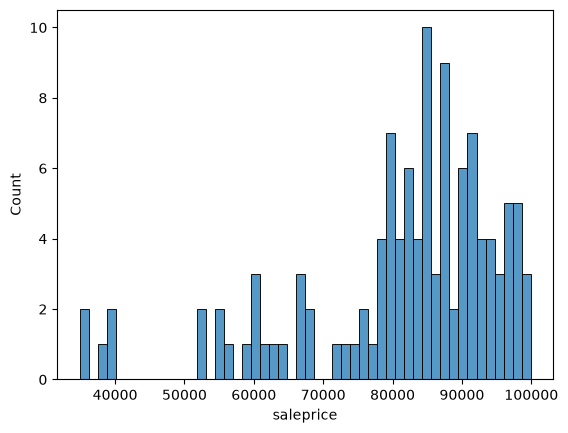

In [15]:
sns.histplot(data=df[df['saleprice'] < 100000], x='saleprice', bins=50)

### Приводим цены к нормальному распределению через log1p

<Axes: xlabel='saleprice', ylabel='Count'>

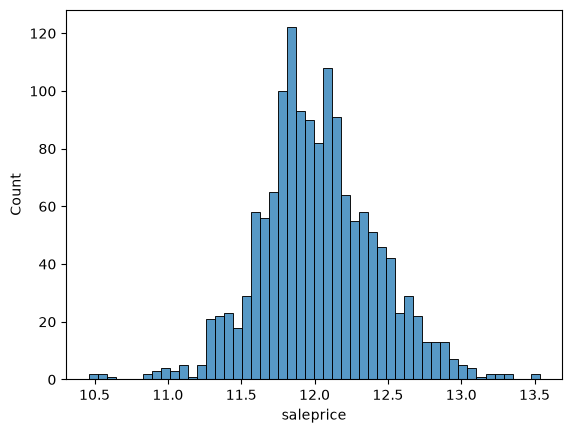

In [16]:
import numpy as np
price_logs = np.log1p(df.saleprice)
sns.histplot(price_logs, bins=50)

### Считаем пропущенные значения

In [17]:
df.isnull().sum()

id                  0
mssubclass          0
mszoning            4
lotfrontage       486
lotarea             0
                 ... 
mosold              0
yrsold              0
saletype            1
salecondition       0
saleprice        1459
Length: 81, dtype: int64

### Деление данных и реализация функции с Ridge регрессией

In [18]:
import numpy as np
import pandas as pd

# Восстанавливаем границу
df_train_full = df.iloc[:train_len].reset_index(drop=True)   # только train

n = len(df_train_full)
n_val  = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

idx = np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)

df_train = df_train_full.iloc[idx[:n_train]].reset_index(drop=True)
df_val   = df_train_full.iloc[idx[n_train:n_train+n_val]].reset_index(drop=True)
df_test  = df_train_full.iloc[idx[n_train+n_val:]].reset_index(drop=True)

print("Размеры:", len(df_train), len(df_val), len(df_test))


y_train = np.log1p(df_train['saleprice'].values)
y_val   = np.log1p(df_val['saleprice'].values)
y_test  = np.log1p(df_test['saleprice'].values)

# Удаляем целевую переменную из признаков
df_train = df_train.drop(columns=['saleprice'], errors='ignore')
df_val   = df_val.drop(columns=['saleprice'], errors='ignore')
df_test  = df_test.drop(columns=['saleprice'], errors='ignore')

# --- Проверка колонок из base ---
base = [
    'mssubclass','lotarea','overallqual','overallcond','yearbuilt','yearremodadd',
    '1stflrsf','2ndflrsf','lowqualfinsf','grlivarea','fullbath','halfbath',
    'bedroomabvgr','kitchenabvgr','totrmsabvgrd','fireplaces','wooddecksf',
    'openporchsf','enclosedporch','3ssnporch','screenporch','poolarea',
    'miscval','mosold','yrsold', 'garagecars', 'garagearea', 'totalbsmtsf', 'masvnrarea', 'bsmtfinsf1', 'bsmtfinsf2',
    'bsmtunfsf', 'bsmtfullbath', 'bsmthalfbath', 'garageyrblt', 
]

missing = set(base) - set(df_train.columns)
if missing:
    print("Отсутствуют колонки:", missing)
else:
    print("Все колонки из base найдены.")


X_train = df_train[base].fillna(0).astype(float).values
X_val   = df_val[base].fillna(0).astype(float).values
X_test  = df_test[base].fillna(0).astype(float).values

print("Есть NaN в X_train?", np.any(np.isnan(X_train)))
print("Есть inf в X_train?", np.any(np.isinf(X_train)))

def train_linear_regression_ridge(X, y, alpha=1.0):
    # Добавляем столбец единиц для intercept
    ones = np.ones((X.shape[0], 1))
    X_aug = np.hstack([ones, X])
    
    n_features = X_aug.shape[1]
    
    # XTX + αI
    XTX = X_aug.T @ X_aug
    reg = alpha * np.eye(n_features)
    reg[0, 0] = 0                     
    
    XTX_reg = XTX + reg
    w_full = np.linalg.inv(XTX_reg) @ X_aug.T @ y
    
    return w_full[0], w_full[1:]


Размеры: 876 292 292
Все колонки из base найдены.
Есть NaN в X_train? False
Есть inf в X_train? False


### Процесс обучения и вывод весов

In [19]:
w0, w = train_linear_regression_ridge(X_train, y_train)
print("Intercept (w0):", w0)
print("Coefficients (w):", w)

Intercept (w0): 16.281555895136094
Coefficients (w): [-6.38309036e-04  1.94755797e-06  8.78221173e-02  5.01636638e-02
  2.93475086e-03  1.00366070e-03 -6.54544375e-04 -6.64547779e-04
 -7.02024806e-04  7.73606173e-04  5.37248279e-02  2.23900326e-02
  7.84635715e-03 -5.28145860e-02  2.13624884e-02  5.34706767e-02
  1.48224855e-04  9.04626467e-08  1.20365997e-04  5.44738429e-05
  4.24506244e-04 -5.38315614e-04 -1.34254016e-06 -3.57311387e-04
 -6.71691986e-03  6.84471953e-02  2.67219355e-06  4.48148373e-05
  1.98510190e-05  2.26998873e-05  3.35867864e-06  1.87595266e-05
  8.00047190e-02  2.97503025e-02 -3.90448511e-06]


### График истинных значений vs предсказанных

<Axes: ylabel='Count'>

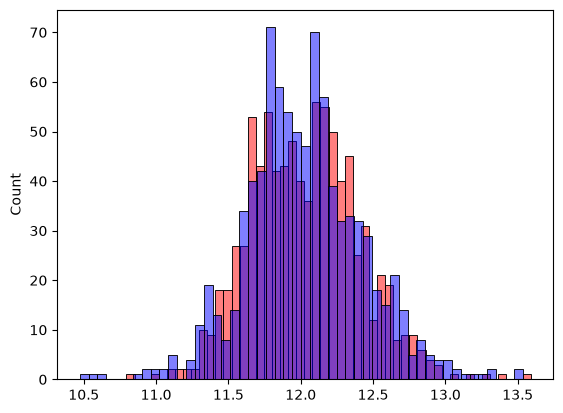

In [21]:
y_pred = w0 + X_train.dot(w)

sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

### Функция квадратичной ошибки и проверка среднеквадратичной ошибки при alpha = 1.0 на обучающих данных

In [111]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)


rmse(y_train, y_pred)

np.float64(0.15327665005195637)

### Оцениваем масштабы признаков

In [112]:
print("Масштабы признаков:")
for i, col in enumerate(base):
    print(f"{col:>15}: mean={X_train[:,i].mean():>10.2f}, std={X_train[:,i].std():>10.2f}")

Масштабы признаков:
     mssubclass: mean=     55.46, std=     40.30
        lotarea: mean=  10479.36, std=   8304.38
    overallqual: mean=      6.12, std=      1.41
    overallcond: mean=      5.55, std=      1.10
      yearbuilt: mean=   1972.24, std=     29.81
   yearremodadd: mean=   1985.54, std=     20.33
       1stflrsf: mean=   1165.53, std=    401.25
       2ndflrsf: mean=    348.14, std=    431.72
   lowqualfinsf: mean=      5.79, std=     47.27
      grlivarea: mean=   1519.46, std=    533.22
       fullbath: mean=      1.57, std=      0.55
       halfbath: mean=      0.39, std=      0.51
   bedroomabvgr: mean=      2.86, std=      0.81
   kitchenabvgr: mean=      1.04, std=      0.22
   totrmsabvgrd: mean=      6.52, std=      1.59
     fireplaces: mean=      0.62, std=      0.64
     wooddecksf: mean=     92.81, std=    120.05
    openporchsf: mean=     43.70, std=     59.97
  enclosedporch: mean=     21.18, std=     58.52
      3ssnporch: mean=      3.61, std=     29.01


### Стандартизируем признаки

In [113]:
mean = X_train.mean(axis=0)
std  = X_train.std(axis=0)
std[std == 0] = 1   # защита от деления на ноль (если признак константный)

X_train_s = (X_train - mean) / std
X_val_s   = (X_val   - mean) / std
X_test_s  = (X_test  - mean) / std

### Подбор лучшего alpha на данных валидации

In [114]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

best_alpha, best_rmse = None, np.inf

for alpha in alphas:
    w0_, w_ = train_linear_regression_ridge(X_train_s, y_train, alpha=alpha)
    rmse_val = rmse(y_val, w0_ + X_val_s @ w_)
    print(f"alpha={alpha:>8}: RMSE val = {rmse_val:.5f}")
    if rmse_val < best_rmse:
        best_rmse, best_alpha = rmse_val, alpha

print(f"\nBest alpha = {best_alpha}, RMSE val = {best_rmse:.5f}")

alpha=  0.0001: RMSE val = 0.14001
alpha=   0.001: RMSE val = 0.14001
alpha=    0.01: RMSE val = 0.14001
alpha=     0.1: RMSE val = 0.14000
alpha=     1.0: RMSE val = 0.14000
alpha=    10.0: RMSE val = 0.13994
alpha=   100.0: RMSE val = 0.14137

Best alpha = 10.0, RMSE val = 0.13994


### Вывод RMSE на train/val/test с учетом Best alpha = 0.0001

In [115]:
w0, w = train_linear_regression_ridge(X_train_s, y_train, alpha=0.0001)

rmse_train = rmse(y_train, w0 + X_train_s @ w)
rmse_val   = rmse(y_val,   w0 + X_val_s   @ w)
rmse_test  = rmse(y_test,  w0 + X_test_s  @ w)

print(f"RMSE train: {rmse_train:.5f}")
print(f"RMSE val:   {rmse_val:.5f}")
print(f"RMSE test:  {rmse_test:.5f}")
print(f"Признаков в X_train_s: {X_train_s.shape[1]}")

RMSE train: 0.15328
RMSE val:   0.14001
RMSE test:  0.13425
Признаков в X_train_s: 35


### Подсчет категориальных колонок и других типов признаков

In [117]:
strings = list(df.select_dtypes(include=['object']).columns)
print(f"Категориальных колонок: {len(strings)}")
print(df.dtypes.value_counts())

Категориальных колонок: 43
str        43
int64      26
float64    12
Name: count, dtype: int64


G:\TEMP\ipykernel_76832\3740439315.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  strings = list(df.select_dtypes(include=['object']).columns)


### Анализ категориальных переменных

In [118]:
categorical = df.select_dtypes(include=['object']).columns.tolist()

print(f"{'Колонка':>20} {'Уникальных':>12} {'NaN %':>8} {'Примеры':>45}")
print("-" * 90)

for col in categorical:
    n = df[col].nunique()
    nan_pct = df[col].isna().mean() * 100
    examples = list(df[col].dropna().unique()[:3])
    print(f"{col:>20} {n:>12} {nan_pct:>7.1f}% {str(examples):>45}")

             Колонка   Уникальных    NaN %                                       Примеры
------------------------------------------------------------------------------------------
            mszoning            5     0.1%                       ['rl', 'rm', 'c_(all)']
              street            2     0.0%                              ['pave', 'grvl']
               alley            2    93.2%                              ['grvl', 'pave']
            lotshape            4     0.0%                         ['reg', 'ir1', 'ir2']
         landcontour            4     0.0%                         ['lvl', 'bnk', 'low']
           utilities            2     0.1%                          ['allpub', 'nosewa']
           lotconfig            5     0.0%                   ['inside', 'fr2', 'corner']
           landslope            3     0.0%                         ['gtl', 'mod', 'sev']
        neighborhood           25     0.0%             ['collgcr', 'veenker', 'crawfor']
          condition

G:\TEMP\ipykernel_76832\3528196091.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=['object']).columns.tolist()


### Используемые категориальные переменные и one-hot encoding

In [130]:
categorical_to_use = [
    'neighborhood', 'housestyle', 'saletype', 'mszoning',
    'bsmtqual', 'bsmtexposure', 'bsmtfintype1',
    'heatingqc', 'centralair', 'kitchenqual',
    'exterqual', 'extercond', 'garagetype', 'garagefinish',
    'foundation', 'bldgtype', 'salecondition',   
]

# Собираем топ-N для каждой
categories = {}
for c in categorical_to_use:
    n_top = 10 if c == 'neighborhood' else df_train_full[c].nunique()
    categories[c] = list(df_train_full[c].value_counts().head(n_top).index)

# Создаём one-hot
for c, values in categories.items():
    for v in values:
        df_train_full[f"{c}_{v}"] = (df_train_full[c] == v).astype(int)

# Расширяем base
base_extended = base.copy()
for c, values in categories.items():
    for v in values:
        base_extended.append(f"{c}_{v}")

print(f"Признаков: было {len(base)}, стало {len(base_extended)}")


# 1. Индексы сплита — те же, что были
idx = np.arange(len(df_train_full))
np.random.seed(42)
np.random.shuffle(idx)

n = len(df_train_full)
n_val, n_test = int(n * 0.2), int(n * 0.2)
n_train = n - n_val - n_test

# 2. Пересоздаём срезы — теперь С one-hot колонками
df_train = df_train_full.iloc[idx[:n_train]].reset_index(drop=True)
df_val   = df_train_full.iloc[idx[n_train:n_train+n_val]].reset_index(drop=True)
df_test  = df_train_full.iloc[idx[n_train+n_val:]].reset_index(drop=True)

Признаков: было 35, стало 127


### Финальная модель с числовыми+категориальными признаками и RMSE на трех выборках

In [145]:
# ===== 3. y =====
y_train = np.log1p(df_train['saleprice'].values)
y_val   = np.log1p(df_val['saleprice'].values)
y_test  = np.log1p(df_test['saleprice'].values)

# ===== 4. X с base_extended =====
X_train = df_train[base_extended].fillna(0).astype(float).values
X_val   = df_val[base_extended].fillna(0).astype(float).values
X_test  = df_test[base_extended].fillna(0).astype(float).values

print(f"X_train: {X_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"X_test:  {X_test.shape}")

# ===== 5. Стандартизация =====
mean = X_train.mean(axis=0)
std  = X_train.std(axis=0)
std[std == 0] = 1

X_train_s = (X_train - mean) / std
X_val_s   = (X_val   - mean) / std
X_test_s  = (X_test  - mean) / std

# ===== 6. Подбор alpha =====
for alpha in [0.1, 1.0, 10.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0]:
    w0_, w_ = train_linear_regression_ridge(X_train_s, y_train, alpha=alpha)
    rmse_val = rmse(y_val, w0_ + X_val_s @ w_)
    print(f"alpha={alpha:>8}: RMSE val = {rmse_val:.5f}")

# ===== 7. Финальная модель =====
w0, w = train_linear_regression_ridge(X_train_s, y_train, alpha=100)

print(f"\nRMSE train: {rmse(y_train, w0 + X_train_s @ w):.5f}")
print(f"RMSE val:   {rmse(y_val,   w0 + X_val_s   @ w):.5f}")
print(f"RMSE test:  {rmse(y_test,  w0 + X_test_s  @ w):.5f}")

X_train: (876, 127)
X_val:   (292, 127)
X_test:  (292, 127)
alpha=     0.1: RMSE val = 0.14189
alpha=     1.0: RMSE val = 0.14178
alpha=    10.0: RMSE val = 0.14089
alpha=   100.0: RMSE val = 0.13838
alpha=   300.0: RMSE val = 0.14013
alpha=  1000.0: RMSE val = 0.15308
alpha=  3000.0: RMSE val = 0.18563
alpha= 10000.0: RMSE val = 0.25450

RMSE train: 0.12970
RMSE val:   0.13838
RMSE test:  0.12585


### Переобучение на всем train.csv чтобы точность была больше

In [149]:
# ===== ШАГ 4: Переобучение на ВСЁМ train =====
X_full = df_train_full[base_extended].fillna(0).astype(float).values
y_full = np.log1p(df_train_full['saleprice'].values)

print(f"X_full: {X_full.shape}")   # (1460, 127)

mean_full = X_full.mean(axis=0)
std_full  = X_full.std(axis=0)
std_full[std_full == 0] = 1
X_full_s  = (X_full - mean_full) / std_full

w0_full, w_full = train_linear_regression_ridge(X_full_s, y_full, alpha=100)

print(f"w0_full: {w0_full:.4f}")
print(f"Средний |w_full|: {np.abs(w_full).mean():.4f}")

rmse_train_full = rmse(y_full, w0_full + X_full_s @ w_full)
print(f"RMSE на полных данных (1460): {rmse_train_full}")
print(f"RMSE train на неполных данных: {rmse(y_train, w0 + X_train_s @ w):.5f}")

X_full: (1460, 127)
w0_full: 12.0241
Средний |w_full|: 0.0096
RMSE на полных данных (1460): 0.12505698674041887
RMSE train на неполных данных: 0.12970


### Загружаем test.csv

In [152]:
# ===== Загружаем ИСХОДНЫЙ test.csv =====
test_kaggle = pd.read_csv('test.csv')

print(f"test.csv форма: {test_kaggle.shape}")   # (1459, 80)
print(f"saleprice? {'saleprice' in test_kaggle.columns}")   # False
print(f"Первые 5 Id: {test_kaggle['Id'].head().tolist()}")  # [1461..1465]

test.csv форма: (1459, 80)
saleprice? False
Первые 5 Id: [1461, 1462, 1463, 1464, 1465]


### Базовая предобработка test.csv (по аналогии как выше)

In [ ]:
# Колонки: lower + replace
test_kaggle.columns = test_kaggle.columns.str.lower().str.replace(' ', '_')

# Строковые значения: lower + replace
strings_test = list(test_kaggle.select_dtypes(include=['object']).columns)
for col in strings_test:
    test_kaggle[col] = test_kaggle[col].str.lower().str.replace(' ', '_')

print(f"Строковых: {len(strings_test)}")
print(f"Колонок: {len(test_kaggle.columns)}")

# Умное заполнение NaN
test_kaggle['lotfrontage']  = test_kaggle['lotfrontage'].fillna(df_train_full['lotfrontage'].median())
test_kaggle['masvnrarea']   = test_kaggle['masvnrarea'].fillna(0)
test_kaggle['garageyrblt']  = test_kaggle['garageyrblt'].fillna(test_kaggle['yearbuilt'])
test_kaggle['bsmtfinsf1']   = test_kaggle['bsmtfinsf1'].fillna(0)
test_kaggle['bsmtfinsf2']   = test_kaggle['bsmtfinsf2'].fillna(0)
test_kaggle['bsmtunfsf']    = test_kaggle['bsmtunfsf'].fillna(0)
test_kaggle['bsmtfullbath'] = test_kaggle['bsmtfullbath'].fillna(0)
test_kaggle['bsmthalfbath'] = test_kaggle['bsmthalfbath'].fillna(0)

print("NaN заполнены")

# One-hot теми же categories
for c, values in categories.items():
    for v in values:
        test_kaggle[f"{c}_{v}"] = (test_kaggle[c] == v).astype(int)

# Проверка
missing = set(base_extended) - set(test_kaggle.columns)
print(f"Отсутствуют: {missing if missing else 'нет'}")
print(f"Колонок в test_kaggle: {len(test_kaggle.columns)}")




Строковых: 43
Колонок: 172
NaN заполнены
Отсутствуют: нет
Колонок в test_kaggle: 172
['mssubclass', 'lotarea', 'overallqual', 'overallcond', 'yearbuilt', 'yearremodadd', '1stflrsf', '2ndflrsf', 'lowqualfinsf', 'grlivarea', 'fullbath', 'halfbath', 'bedroomabvgr', 'kitchenabvgr', 'totrmsabvgrd', 'fireplaces', 'wooddecksf', 'openporchsf', 'enclosedporch', '3ssnporch', 'screenporch', 'poolarea', 'miscval', 'mosold', 'yrsold', 'garagecars', 'garagearea', 'totalbsmtsf', 'masvnrarea', 'bsmtfinsf1', 'bsmtfinsf2', 'bsmtunfsf', 'bsmtfullbath', 'bsmthalfbath', 'garageyrblt', 'neighborhood_names', 'neighborhood_collgcr', 'neighborhood_oldtown', 'neighborhood_edwards', 'neighborhood_somerst', 'neighborhood_gilbert', 'neighborhood_nridght', 'neighborhood_sawyer', 'neighborhood_nwames', 'neighborhood_sawyerw', 'housestyle_1story', 'housestyle_2story', 'housestyle_1.5fin', 'housestyle_slvl', 'housestyle_sfoyer', 'housestyle_1.5unf', 'housestyle_2.5unf', 'housestyle_2.5fin', 'saletype_wd', 'saletype_ne

G:\TEMP\ipykernel_76832\3282933303.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  strings_test = list(test_kaggle.select_dtypes(include=['object']).columns)


### Стандартизация как в train.csv и просмотр диапазонов предсказанных цен через min/max/mean/median и поиск NaN

In [161]:
# X_kaggle
X_kaggle = test_kaggle[base_extended].fillna(0).astype(float).values
print(f"X_kaggle: {X_kaggle.shape}")   # (1459, 127)

# Стандартизация ТЕМИ ЖЕ mean_full/std_full (от 1460!)
X_kaggle_s = (X_kaggle - mean_full) / std_full

# Предсказание
y_pred_full = np.expm1(w0_full + X_kaggle_s @ w_full)


# Проверка
print(f"\ny_pred_full диапазон:")
print(f"  min:    {y_pred_full.min():>12,.0f}")
print(f"  max:    {y_pred_full.max():>12,.0f}")
print(f"  mean:   {y_pred_full.mean():>12,.0f}")
print(f"  median: {np.median(y_pred_full):>12,.0f}")
print(f"  NaN:    {np.isnan(y_pred_full).sum()}")

X_kaggle: (1459, 127)

y_pred_full диапазон:
  min:          40,738
  max:         814,143
  mean:        178,058
  median:      158,812
  NaN:    0


### Конечный submission

In [162]:
submission_full = pd.DataFrame({
    'Id': test_kaggle['id'],
    'SalePrice': y_pred_full
})
submission_full.to_csv('submission_full.csv', index=False)

print(submission_full.head(10))
print(f"Форма: {submission_full.shape}")
print(f"Колонки: {submission_full.columns.tolist()}")
print(f"NaN: {submission_full.isna().sum().sum()}")

     Id      SalePrice
0  1461  125184.673498
1  1462  141614.874436
2  1463  169989.313396
3  1464  192199.886008
4  1465  186696.051467
5  1466  168452.147360
6  1467  184115.069183
7  1468  161191.221104
8  1469  193349.936482
9  1470  119846.937031
Форма: (1459, 2)
Колонки: ['Id', 'SalePrice']
NaN: 0
